<a href="https://colab.research.google.com/github/castr1x/ML_an.nykoliuk_3-12/blob/main/%D0%9B%D0%A0_8_%D0%9C%D0%9D_%D0%9A%D0%BB%D0%B0%D1%81%D1%82%D0%B5%D1%80%D0%B8%D0%B7%D0%B0%D1%86%D1%96%D1%8F_%D0%9D%D0%B8%D0%BA%D0%BE%D0%BB%D1%8E%D0%BA_%D0%A4%D0%86%D0%A2_3_12.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота № 8
## Методи кластеризації: K-Means, метод ліктя, коефіцієнт силуета та PCA

**Мета:** навчитися застосовувати алгоритм K-Means, добирати кількість кластерів за допомогою методу ліктя та коефіцієнта силуета; дослідити використання PCA. Додатково — порівняти моделі класифікації на наборі даних про студентів (цей етап збережено з початкової роботи).

**Середовище:** Google Colab або Jupyter Notebook із Python. Для завдання 2 потрібно завантажити набір даних з кагл https://www.kaggle.com/datasets/rabieelkharoua/students-performance-dataset?select=Student_performance_data+_.csv.

**Виконання:** запускайте комірки послідовно, зверху вниз.

## Завдання 1. Кластеризація набору даних Iris

**1.1. Імпорт бібліотек.** Імпортуйте `matplotlib`, `pandas`, `seaborn`, `load_iris`, `KMeans`, `silhouette_score` і `StandardScaler`.

In [5]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

**1.2. Завантаження Iris.** Завантажте Iris та виведіть перші п’ять рядків таблиці з назвами ознак.

In [6]:
iris = load_iris(as_frame = True).frame

iris.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


**1.3. Масштабування та метод ліктя.** Стандартизуйте дані та за допомогою методу ліктя визначте оптимальну кількість кластерів

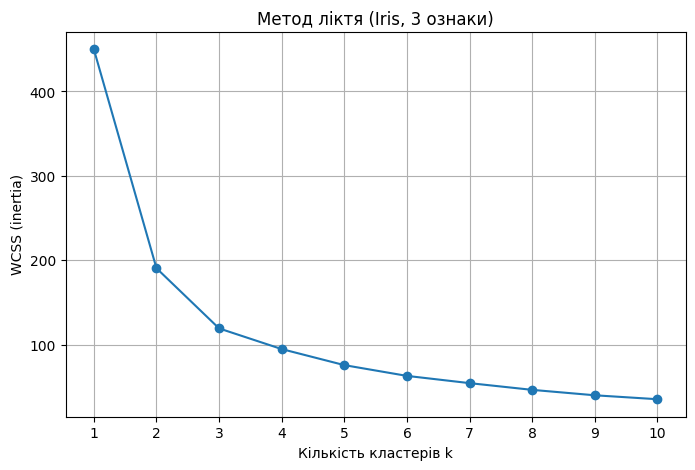

k =  1: WCSS = 450.00
k =  2: WCSS = 190.47
k =  3: WCSS = 119.14
k =  4: WCSS = 94.64
k =  5: WCSS = 75.63
k =  6: WCSS = 62.87
k =  7: WCSS = 54.28
k =  8: WCSS = 46.31
k =  9: WCSS = 39.89
k = 10: WCSS = 35.23


In [7]:
features = ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)']
X_iris = iris[features]

scaler_iris = StandardScaler()
X_iris_scaled = scaler_iris.fit_transform(X_iris)

wcss = []
k_range = range(1, 11)
for k in k_range:
    kmeans = KMeans(n_clusters=k, init='k-means++', n_init=10, random_state=42)
    kmeans.fit(X_iris_scaled)
    wcss.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(k_range, wcss, marker='o')
plt.title('Метод ліктя (Iris, 3 ознаки)')
plt.xlabel('Кількість кластерів k')
plt.ylabel('WCSS (inertia)')
plt.xticks(k_range)
plt.grid(True)
plt.show()

for k, w in zip(k_range, wcss):
    print(f'k = {k:2d}: WCSS = {w:.2f}')

**1.4. Метод силуетів.** Для тих самих трьох ознак Iris обчисліть середній коефіцієнт силуета для 2–10 кластерів і побудуйте графік.

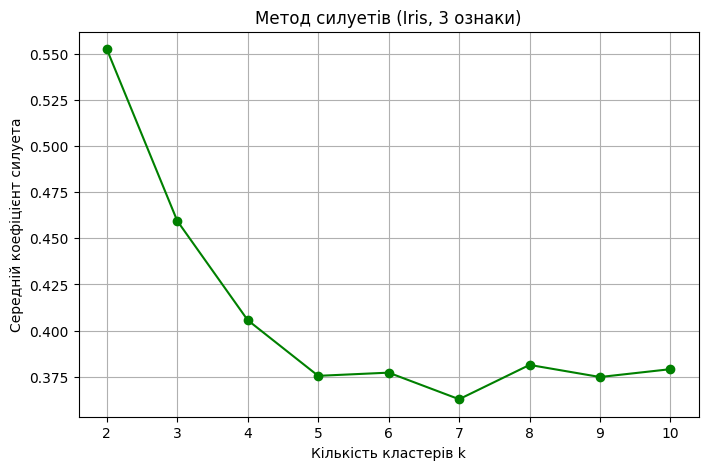

k =  2: silhouette = 0.5525
k =  3: silhouette = 0.4594
k =  4: silhouette = 0.4057
k =  5: silhouette = 0.3755
k =  6: silhouette = 0.3772
k =  7: silhouette = 0.3628
k =  8: silhouette = 0.3814
k =  9: silhouette = 0.3749
k = 10: silhouette = 0.3791

Найбільший коефіцієнт силуета при k = 2


In [8]:
silhouette_scores = []
k_range_sil = range(2, 11)
for k in k_range_sil:
    kmeans = KMeans(n_clusters=k, init='k-means++', n_init=10, random_state=42)
    labels = kmeans.fit_predict(X_iris_scaled)
    silhouette_scores.append(silhouette_score(X_iris_scaled, labels))

plt.figure(figsize=(8, 5))
plt.plot(k_range_sil, silhouette_scores, marker='o', color='green')
plt.title('Метод силуетів (Iris, 3 ознаки)')
plt.xlabel('Кількість кластерів k')
plt.ylabel('Середній коефіцієнт силуета')
plt.xticks(k_range_sil)
plt.grid(True)
plt.show()

for k, s in zip(k_range_sil, silhouette_scores):
    print(f'k = {k:2d}: silhouette = {s:.4f}')
best_k_iris = list(k_range_sil)[silhouette_scores.index(max(silhouette_scores))]
print(f'\nНайбільший коефіцієнт силуета при k = {best_k_iris}')

**1.5. Фінальна кластеризація та візуалізація.** Побудуйте K-Means для `n_clusters=2`  На площині покажіть перші дві з них та відповідні координати центрів. Це **двовимірне відображення результату кластеризації за трьома ознаками**.

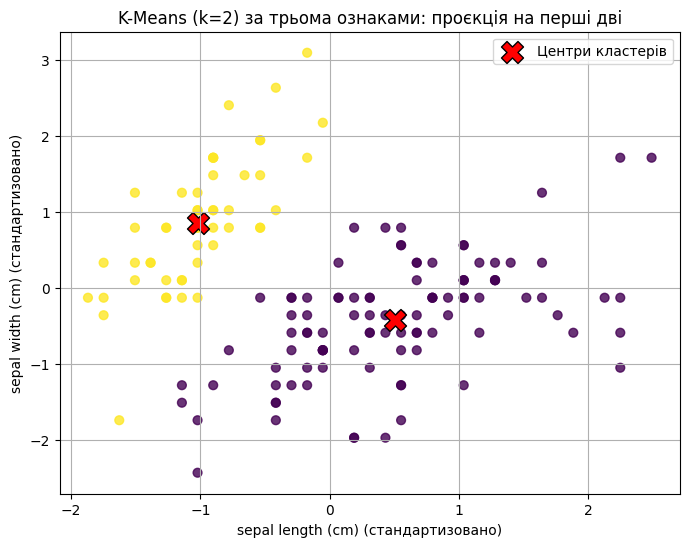

Координати центрів (стандартизовані):
   sepal length (cm)  sepal width (cm)  petal length (cm)
0           0.507289         -0.426631           0.652494
1          -1.014579          0.853263          -1.304987

Кількість об’єктів у кластерах: {0: 100, 1: 50}

Співвідношення кластерів і справжніх класів:
cluster   0   1
target         
0         0  50
1        50   0
2        50   0


In [9]:
kmeans_iris = KMeans(n_clusters=2, init='k-means++', n_init=10, random_state=42)
iris_labels = kmeans_iris.fit_predict(X_iris_scaled)
centers = kmeans_iris.cluster_centers_

plt.figure(figsize=(8, 6))
plt.scatter(X_iris_scaled[:, 0], X_iris_scaled[:, 1], c=iris_labels, cmap='viridis', s=40, alpha=0.8)
plt.scatter(centers[:, 0], centers[:, 1], c='red', marker='X', s=250, edgecolor='black', label='Центри кластерів')
plt.title('K-Means (k=2) за трьома ознаками: проєкція на перші дві')
plt.xlabel(f'{features[0]} (стандартизовано)')
plt.ylabel(f'{features[1]} (стандартизовано)')
plt.legend()
plt.grid(True)
plt.show()

print('Координати центрів (стандартизовані):')
print(pd.DataFrame(centers, columns=features))
print('\nКількість об’єктів у кластерах:', pd.Series(iris_labels).value_counts().sort_index().to_dict())
print('\nСпіввідношення кластерів і справжніх класів:')
print(pd.crosstab(iris['target'], iris_labels, rownames=['target'], colnames=['cluster']))

**Короткий висновок до завдання 1:** порівняйте результати методу ліктя й методу силуетів. Поясніть, чому обрано два кластери та чи збігається такий вибір з отриманими графіками.

## Завдання 2. Дослідження даних студентів

Спочатку порівняйте три класифікатори (як у початковій лабораторній роботі), а потім виконайте кластеризацію. **Класифікація та кластеризація — різні задачі:** у класифікації використовується цільова ознака `GradeClass`, а в кластеризації — ні.

**2.1. Імпорт бібліотек для класифікації.** Імпортуйте засоби для поділу даних, добору параметрів, класифікації та оцінювання моделей.

In [10]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report
import os

from google.colab import files

**2.2. Завантаження файлу.** Помістіть `Student_data.csv` до робочої папки або завантажте його через Colab. Файл містить дані з Вашої початкової роботи.

In [11]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("rabieelkharoua/students-performance-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'students-performance-dataset' dataset.
Path to dataset files: /kaggle/input/students-performance-dataset


**2.3. Перегляд даних.** Прочитайте CSV у DataFrame і перегляньте вміст.

In [12]:
# Вивід даних з файлу
df = pd.read_csv(os.path.join(path,'Student_performance_data _.csv'))
df.head()

,StudentID,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA,GradeClass
0,1001,17,1,0,2,19.833723,7,1,2,0,0,1,0,2.929196,2.0
1,1002,18,0,0,1,15.408756,0,0,1,0,0,0,0,3.042915,1.0
2,1003,15,0,2,3,4.210570,26,0,2,0,0,0,0,0.112602,4.0
3,1004,17,1,0,3,10.028829,14,0,3,1,0,0,0,2.054218,3.0
4,1005,17,1,0,2,4.672495,17,1,3,0,0,0,0,1.288061,4.0


**2.4. Назви стовпців.** Виведіть назви всіх стовпців.

In [13]:
for c in df.columns:
  print(c,'\n')

StudentID 

Age 

Gender 

Ethnicity 

ParentalEducation 

StudyTimeWeekly 

Absences 

Tutoring 

ParentalSupport 

Extracurricular 

Sports 

Music 

Volunteering 

GPA 

GradeClass 



**2.5. Структура таблиці.** Перегляньте типи стовпців і кількість непорожніх значень.

In [14]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2392 entries, 0 to 2391
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   StudentID          2392 non-null   int64  
 1   Age                2392 non-null   int64  
 2   Gender             2392 non-null   int64  
 3   Ethnicity          2392 non-null   int64  
 4   ParentalEducation  2392 non-null   int64  
 5   StudyTimeWeekly    2392 non-null   float64
 6   Absences           2392 non-null   int64  
 7   Tutoring           2392 non-null   int64  
 8   ParentalSupport    2392 non-null   int64  
 9   Extracurricular    2392 non-null   int64  
 10  Sports             2392 non-null   int64  
 11  Music              2392 non-null   int64  
 12  Volunteering       2392 non-null   int64  
 13  GPA                2392 non-null   float64
 14  GradeClass         2392 non-null   float64
dtypes: float64(3), int64(12)
memory usage: 280.4 KB


**2.6. Пропущені значення.** Перевірте, чи містить набір даних пропущені значення.

In [15]:
print(df.isnull().sum())
print('\nВсього пропущених значень:', df.isnull().sum().sum())

StudentID            0
Age                  0
Gender               0
Ethnicity            0
ParentalEducation    0
StudyTimeWeekly      0
Absences             0
Tutoring             0
ParentalSupport      0
Extracurricular      0
Sports               0
Music                0
Volunteering         0
GPA                  0
GradeClass           0
dtype: int64

Всього пропущених значень: 0


**2.7. Дублікати.** Обчисліть кількість дублікатів.

In [16]:
print('Кількість дублікатів:', df.duplicated().sum())

Кількість дублікатів: 0


**2.8. Описова статистика.** Виведіть основні описові статистики.

In [17]:
df.describe()

,StudentID,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA,GradeClass
count,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000
mean,2196.500000,16.468645,0.510870,0.877508,1.746237,9.771992,14.541388,0.301421,2.122074,0.383361,0.303512,0.196906,0.157191,1.906186,2.983696
std,690.655244,1.123798,0.499986,1.028476,1.000411,5.652774,8.467417,0.458971,1.122813,0.486307,0.459870,0.397744,0.364057,0.915156,1.233908
min,1001.000000,15.000000,0.000000,0.000000,0.000000,0.001057,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1598.750000,15.000000,0.000000,0.000000,1.000000,5.043079,7.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.174803,2.000000
50%,2196.500000,16.000000,1.000000,0.000000,2.000000,9.705363,15.000000,0.000000,2.000000,0.000000,0.000000,0.000000,0.000000,1.893393,4.000000
75%,2794.250000,17.000000,1.000000,2.000000,2.000000,14.408410,22.000000,1.000000,3.000000,1.000000,1.000000,0.000000,0.000000,2.622216,4.000000
max,3392.000000,18.000000,1.000000,3.000000,4.000000,19.978094,29.000000,1.000000,4.000000,1.000000,1.000000,1.000000,1.000000,4.000000,4.000000


**2.9. Підготовка даних для класифікації.** Сформуйте `X` та `y`, прибравши з ознак цільову змінну `GradeClass` і службовий ідентифікатор `StudentID`. Поділіть дані у співвідношенні 80/20 та стандартизуйте ознаки.

In [18]:
X = df.drop(columns=['StudentID', 'GradeClass'])
y = df['GradeClass']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


### 2.10. Класифікація: Random Forest

**Модель Random Forest.** Здійсніть добір гіперпараметрів `GridSearchCV` (5 згорток), виведіть найкращі параметри, середню CV-точність і тестову accuracy. Пошук може тривати довше через велику сітку параметрів.

In [19]:
rf_param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
}

rf_grid = GridSearchCV(RandomForestClassifier(random_state=42), rf_param_grid,
                       cv=5, scoring='accuracy', n_jobs=-1)
rf_grid.fit(X_train_scaled, y_train)

rf_best = rf_grid.best_estimator_
rf_cv = rf_grid.best_score_
rf_test = accuracy_score(y_test, rf_best.predict(X_test_scaled))

print('Найкращі параметри RF:', rf_grid.best_params_)
print(f'Середня CV-точність: {rf_cv:.4f}')
print(f'Тестова accuracy:    {rf_test:.4f}')

Найкращі параметри RF: {'max_depth': 10, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 200}
Середня CV-точність: 0.9211
Тестова accuracy:    0.9102


### 2.11. Класифікація: Logistic Regression

**Модель Logistic Regression.** Застосуйте `GridSearchCV` до логістичної регресії. Для багатокласової задачі використайте `saga` — `liblinear` у нових версіях sklearn не підтримує багатокласову класифікацію без додаткової обгортки.

In [20]:
# У sklearn 1.8 параметр penalty застарів: тип регуляризації задається через l1_ratio
# (l1_ratio=0 -> L2, l1_ratio=1 -> L1, проміжні значення -> elastic-net)
lr_param_grid = {
    'C': [0.01, 0.1, 1, 10, 100],
    'l1_ratio': [0, 0.5, 1],
}

lr_grid = GridSearchCV(LogisticRegression(solver='saga', max_iter=5000, random_state=42),
                       lr_param_grid, cv=5, scoring='accuracy', n_jobs=-1)
lr_grid.fit(X_train_scaled, y_train)

lr_best = lr_grid.best_estimator_
lr_cv = lr_grid.best_score_
lr_test = accuracy_score(y_test, lr_best.predict(X_test_scaled))

print('Найкращі параметри LR:', lr_grid.best_params_)
print(f'Середня CV-точність: {lr_cv:.4f}')
print(f'Тестова accuracy:    {lr_test:.4f}')

Найкращі параметри LR: {'C': 100, 'l1_ratio': 0}
Середня CV-точність: 0.7977
Тестова accuracy:    0.7912


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1196: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got (penalty=l2)
  warnings.warn(


### 2.12. Класифікація: Support Vector Machine

**Модель SVM.** Виконайте підбір параметрів SVM та обчисліть CV-точність і тестову accuracy.

In [21]:
svm_param_grid = {
    'C': [0.1, 1, 10, 100],
    'kernel': ['linear', 'rbf'],
    'gamma': ['scale', 0.01, 0.1],
}

svm_grid = GridSearchCV(SVC(random_state=42), svm_param_grid,
                        cv=5, scoring='accuracy', n_jobs=-1)
svm_grid.fit(X_train_scaled, y_train)

svm_best = svm_grid.best_estimator_
svm_cv = svm_grid.best_score_
svm_test = accuracy_score(y_test, svm_best.predict(X_test_scaled))

print('Найкращі параметри SVM:', svm_grid.best_params_)
print(f'Середня CV-точність: {svm_cv:.4f}')
print(f'Тестова accuracy:    {svm_test:.4f}')

Найкращі параметри SVM: {'C': 100, 'gamma': 'scale', 'kernel': 'linear'}
Середня CV-точність: 0.8547
Тестова accuracy:    0.8497


### 2.13. Порівняння результатів

**Порівняння моделей.** Порівняйте тестову точність трьох моделей. Оберіть модель **за найкращою CV-точністю**, а звіт `classification_report` виведіть один раз на тестових даних.

             Модель  CV accuracy  Test accuracy
      Random Forest     0.921071       0.910230
Logistic Regression     0.797695       0.791232
                SVM     0.854677       0.849687


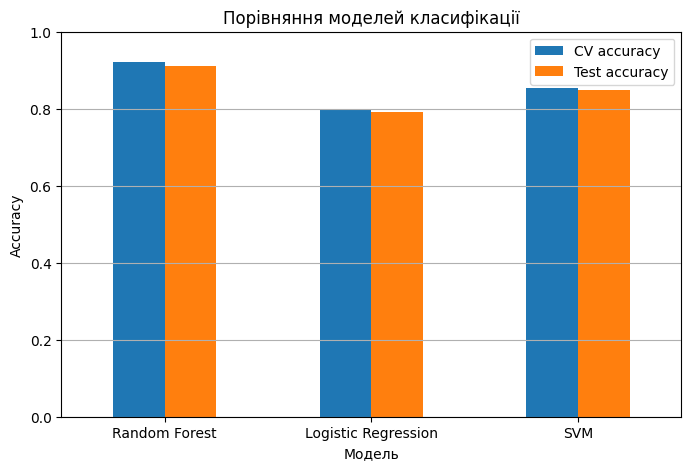


Найкраща модель за CV-точністю: Random Forest


'              precision    recall  f1-score   support\n\n         0.0       1.00      0.29      0.44        21\n         1.0       0.82      0.85      0.84        54\n         2.0       0.89      0.95      0.92        78\n         3.0       0.89      0.89      0.89        83\n         4.0       0.94      0.97      0.96       243\n\n    accuracy                           0.91       479\n   macro avg       0.91      0.79      0.81       479\nweighted avg       0.91      0.91      0.90       479\n'

In [22]:
results = pd.DataFrame({
    'Модель': ['Random Forest', 'Logistic Regression', 'SVM'],
    'CV accuracy': [rf_cv, lr_cv, svm_cv],
    'Test accuracy': [rf_test, lr_test, svm_test],
})
print(results.to_string(index=False))

plt.figure(figsize=(8, 5))
results.set_index('Модель')[['CV accuracy', 'Test accuracy']].plot(kind='bar', ax=plt.gca())
plt.title('Порівняння моделей класифікації')
plt.ylabel('Accuracy')
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.grid(axis='y')
plt.show()

models = {'Random Forest': rf_best, 'Logistic Regression': lr_best, 'SVM': svm_best}
best_name = results.loc[results['CV accuracy'].idxmax(), 'Модель']
best_model = models[best_name]
print(f'\nНайкраща модель за CV-точністю: {best_name}')
classification_report(y_test, best_model.predict(X_test_scaled))

### 2.14. Кластеризація даних студентів: метод ліктя

**Метод ліктя для студентів.** Для кластеризації використайте чотири числові ознаки `Age`, `StudyTimeWeekly`, `Absences`, `GPA`. Стандартизуйте їх і побудуйте графік WCSS для 1–10 кластерів.

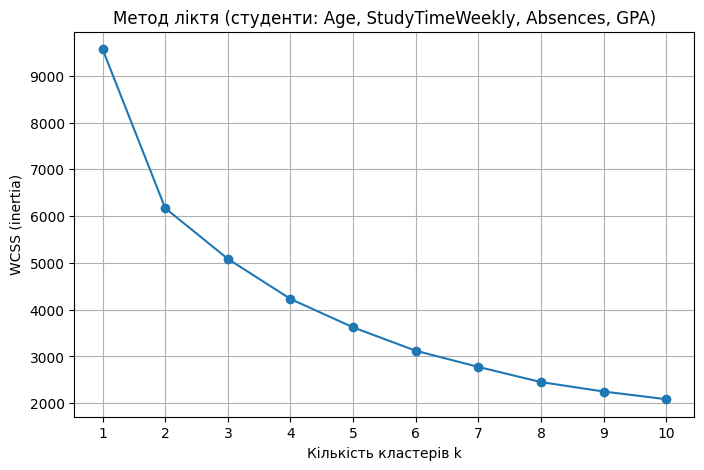

k =  1: WCSS = 9568.00
k =  2: WCSS = 6170.46
k =  3: WCSS = 5086.07
k =  4: WCSS = 4229.41
k =  5: WCSS = 3621.89
k =  6: WCSS = 3122.17
k =  7: WCSS = 2775.91
k =  8: WCSS = 2451.74
k =  9: WCSS = 2250.55
k = 10: WCSS = 2085.60


In [23]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

cluster_features = ['Age', 'StudyTimeWeekly', 'Absences', 'GPA']
X_cluster = StandardScaler().fit_transform(df[cluster_features])

wcss_students = []
for k in range(1, 11):
    km = KMeans(n_clusters=k, init='k-means++', n_init=10, random_state=42)
    km.fit(X_cluster)
    wcss_students.append(km.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), wcss_students, marker='o')
plt.title('Метод ліктя (студенти: Age, StudyTimeWeekly, Absences, GPA)')
plt.xlabel('Кількість кластерів k')
plt.ylabel('WCSS (inertia)')
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()

for k, w in zip(range(1, 11), wcss_students):
    print(f'k = {k:2d}: WCSS = {w:.2f}')

### 2.15. Кластеризація даних студентів: метод силуетів

**Метод силуетів для студентів.** Для тих самих чотирьох ознак побудуйте графік коефіцієнта силуета для 2–10 кластерів.

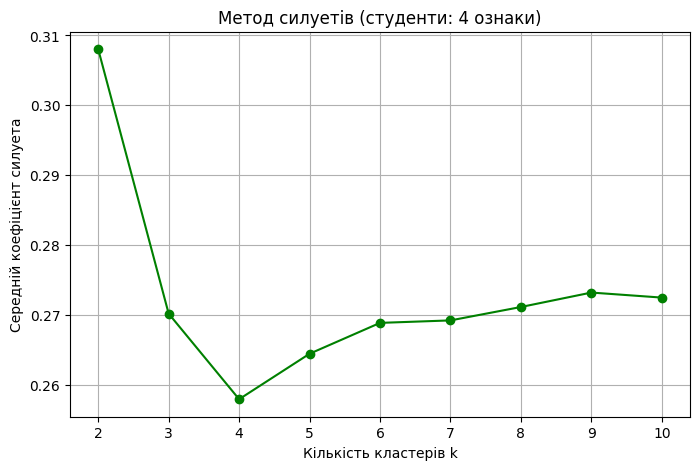

k =  2: silhouette = 0.3080
k =  3: silhouette = 0.2702
k =  4: silhouette = 0.2580
k =  5: silhouette = 0.2645
k =  6: silhouette = 0.2689
k =  7: silhouette = 0.2692
k =  8: silhouette = 0.2712
k =  9: silhouette = 0.2732
k = 10: silhouette = 0.2725

Найбільший коефіцієнт силуета при k = 2


In [24]:
sil_students = []
for k in range(2, 11):
    km = KMeans(n_clusters=k, init='k-means++', n_init=10, random_state=42)
    labels = km.fit_predict(X_cluster)
    sil_students.append(silhouette_score(X_cluster, labels))

plt.figure(figsize=(8, 5))
plt.plot(range(2, 11), sil_students, marker='o', color='green')
plt.title('Метод силуетів (студенти: 4 ознаки)')
plt.xlabel('Кількість кластерів k')
plt.ylabel('Середній коефіцієнт силуета')
plt.xticks(range(2, 11))
plt.grid(True)
plt.show()

for k, s in zip(range(2, 11), sil_students):
    print(f'k = {k:2d}: silhouette = {s:.4f}')
print(f'\nНайбільший коефіцієнт силуета при k = {2 + sil_students.index(max(sil_students))}')

### 2.16. Додатковий підхід: PCA та автоматичне визначення точки ліктя

Тут використовується **інший набір ознак**: усі стовпці, крім `StudentID` та `GradeClass`. Після PCA кластеризацію проведемо за вибраними головними компонентами.

**Установлення додаткових пакетів.** За потреби встановіть `kneed` і `yellowbrick` у середовищі ноутбука.

In [25]:
%pip install -q kneed yellowbrick

**Імпорт PCA і KneeLocator.** Імпортуйте `PCA`, `KneeLocator` та `numpy`.

In [26]:
from sklearn.decomposition import PCA
from kneed import KneeLocator
import numpy as np

**Підготовка всіх ознак.** Приберіть `StudentID` і `GradeClass`, залишивши ознаки для PCA.

In [27]:
X_all = df.drop(columns=['StudentID', 'GradeClass'])
print('Ознаки для PCA:', X_all.columns.tolist())
print('Розмірність:', X_all.shape)

Ознаки для PCA: ['Age', 'Gender', 'Ethnicity', 'ParentalEducation', 'StudyTimeWeekly', 'Absences', 'Tutoring', 'ParentalSupport', 'Extracurricular', 'Sports', 'Music', 'Volunteering', 'GPA']
Розмірність: (2392, 13)


**Модель PCA.** Стандартизуйте ознаки, навчіть PCA та знайдіть частку поясненої дисперсії кожної компоненти.

In [28]:
X_all_scaled = StandardScaler().fit_transform(X_all)

pca = PCA()
pca.fit(X_all_scaled)
explained_variance = pca.explained_variance_ratio_

for i, v in enumerate(explained_variance, start=1):
    print(f'PC{i:2d}: {v:.4f}')

PC 1: 0.1525
PC 2: 0.0861
PC 3: 0.0827
PC 4: 0.0807
PC 5: 0.0786
PC 6: 0.0779
PC 7: 0.0763
PC 8: 0.0760
PC 9: 0.0744
PC10: 0.0738
PC11: 0.0717
PC12: 0.0675
PC13: 0.0018


**Визначення кількості компонент.** Застосуйте `KneeLocator` до часток поясненої дисперсії. У підписі графіка вказуйте номер компоненти без додавання одиниці.

Точка ліктя (кількість головних компонент): 2


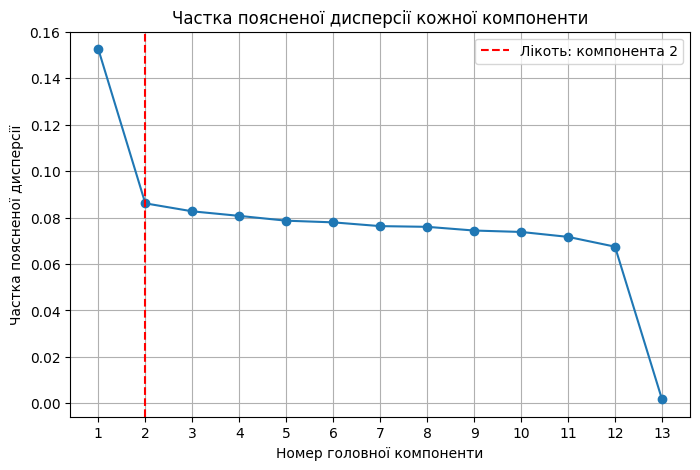

In [29]:
components = np.arange(1, len(explained_variance) + 1)  # номери компонент 1, 2, 3, ...

knee = KneeLocator(components, explained_variance, curve='convex', direction='decreasing')
n_components = int(knee.knee)
print('Точка ліктя (кількість головних компонент):', n_components)

plt.figure(figsize=(8, 5))
plt.plot(components, explained_variance, marker='o')
plt.axvline(n_components, color='red', linestyle='--', label=f'Лікоть: компонента {n_components}')
plt.title('Частка поясненої дисперсії кожної компоненти')
plt.xlabel('Номер головної компоненти')
plt.ylabel('Частка поясненої дисперсії')
plt.xticks(components)
plt.legend()
plt.grid(True)
plt.show()

**Кумулятивна пояснена дисперсія.** На горизонтальній осі має бути **кількість головних компонент** (1, 2, 3, ...), тому індекс масиву для `n_components` дорівнює `n_components - 1`.

**Кумулятивна дисперсія та перетворення PCA.** Побудуйте графік кумулятивної дисперсії та позначте знайдену кількість компонент. Виведіть фактичну частку дисперсії. Перетворіть ознаки через PCA для наступного етапу.

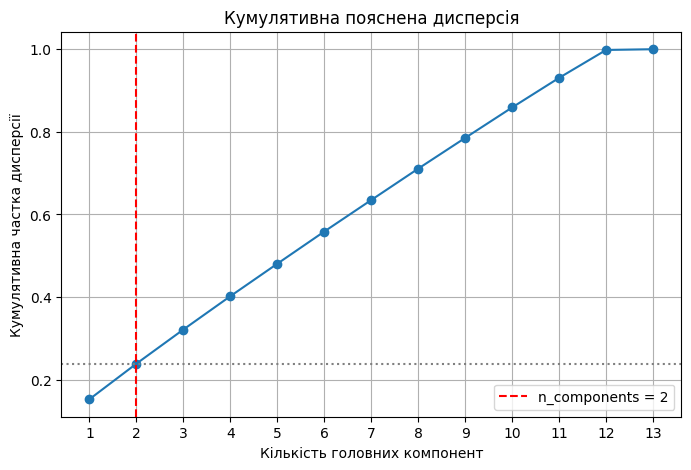

2 компонент(и) пояснюють частку дисперсії: 0.2386
Розмірність після PCA: (2392, 2)


In [30]:
cumulative_variance = np.cumsum(explained_variance)

plt.figure(figsize=(8, 5))
plt.plot(components, cumulative_variance, marker='o')
plt.axvline(n_components, color='red', linestyle='--', label=f'n_components = {n_components}')
plt.axhline(cumulative_variance[n_components - 1], color='gray', linestyle=':')
plt.title('Кумулятивна пояснена дисперсія')
plt.xlabel('Кількість головних компонент')
plt.ylabel('Кумулятивна частка дисперсії')
plt.xticks(components)
plt.legend()
plt.grid(True)
plt.show()

print(f'{n_components} компонент(и) пояснюють частку дисперсії: {cumulative_variance[n_components - 1]:.4f}')

pca_final = PCA(n_components=n_components)
X_pca = pca_final.fit_transform(X_all_scaled)
print('Розмірність після PCA:', X_pca.shape)

Зауваження: кумулятивна пояснена дисперсія — це **частка дисперсії**, а не відсоток «інформативності» даних. Значення потрібно брати з розрахунку, а не задавати наперед (наприклад, 32%).

**Імпорт KElbowVisualizer.** Імпортуйте `KElbowVisualizer` із `yellowbrick.cluster`.

In [31]:
from yellowbrick.cluster import KElbowVisualizer

**Метод ліктя після PCA.** Побудуйте графік `KElbowVisualizer` для K-Means. Для узгодженості з попереднім етапом використайте **дані після PCA**.

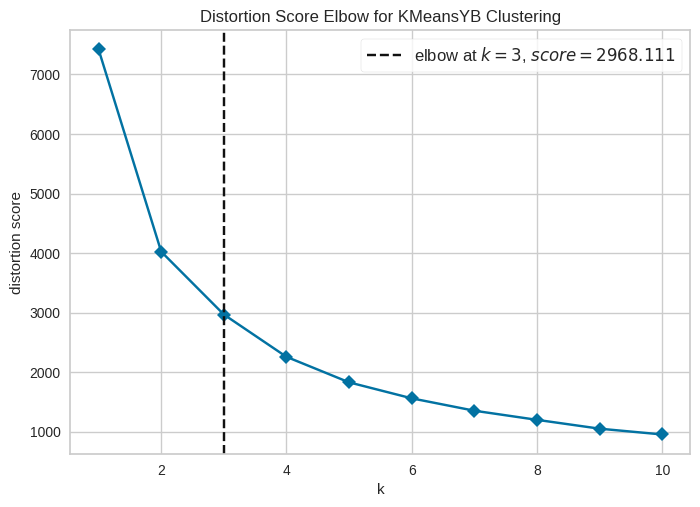

Оптимальна кількість кластерів за KElbowVisualizer: 3


In [32]:
class KMeansYB(KMeans):
    _estimator_type = 'clusterer'

model = KMeansYB(init='k-means++', n_init=10, random_state=42)
visualizer = KElbowVisualizer(model, k=(1, 11), timings=False)
visualizer.fit(X_pca)
visualizer.show()
print('Оптимальна кількість кластерів за KElbowVisualizer:', visualizer.elbow_value_)

## Висновки

Порівняйте результати різних способів визначення кількості кластерів та сформулюйте короткі висновки. Для завдання 2 окремо поясніть різницю між класифікацією за `GradeClass` і кластеризацією без цільової змінної. Зазначте, скільки головних компонент обрано та яку частку дисперсії вони пояснюють.